In [1]:
import numpy as np
import cupy as cp
import cupyx.scipy.signal as signal
import scipy
import pandas as pd

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objs as go
from plotly.subplots import make_subplots

from astropy.modeling import models, fitting
import astropy.units as u
from astropy import constants as const
from astropy.stats import gaussian_sigma_to_fwhm,gaussian_fwhm_to_sigma

import datetime
import pickle
import importlib
import json
import time
import glob
import os
import re

from time_converter import time_converter
# from data.eve_const import wavelength_full,line_name,line_window,initial_guess
from gaussian_fit_eve import gaussian_fit_eve



wavelength_full = np.load('data/wavelength_full.npz')['wavelength_full']
with open('data/selected_band.pkl','rb') as f:
    selected_band = pickle.load(f)


In [3]:
selected_band

,Line Name,Wavelength Range,Temperature,Accurate Wavelength,Initial Guess,Wavelength Index
0,Ni XI 148,"[14.75, 14.93]",6.20,148.377,"[0.00011, 14.84, 0.0424]","[588, 589, 590, 591, 592, 593, 594, 595, 596]"
1,O VI 150,"[14.93, 15.09]",5.50,150.089,"[4.4e-05, 15.01, 0.0424]","[597, 598, 599, 600, 601, 602, 603, 604]"
2,Ni XII 152,"[15.13, 15.35]",6.30,152.151,"[6.5e-05, 15.22, 0.0424]","[607, 608, 609, 610, 611, 612, 613, 614, 615, ..."
3,Fe XXIII 154,"[15.35, 15.53]",7.15,154.303,"[4e-05, 15.42, 0.0424]","[618, 619, 620, 621, 622, 623, 624, 625, 626]"
4,Fe IX 171,"[17, 17.21]",6.20,171.073,"[0.0006, 17.11, 0.0424]","[700, 701, 702, 703, 704, 705, 706, 707, 708, ..."
5,Fe IX 174,"[17.37, 17.59]",6.05,174.531,"[0.00069, 17.45, 0.0424]","[719, 720, 721, 722, 723, 724, 725, 726, 727, ..."
6,Fe X 177,"[17.63, 17.83]",6.05,177.240,"[0.00045, 17.72, 0.0424]","[732, 733, 734, 735, 736, 737, 738, 739, 740, ..."
7,Fe XI 180,"[17.95, 18.15]",6.15,180.401,"[0.0006, 18.05, 0.0424]","[748, 749, 750, 751, 752, 753, 754, 755, 756, ..."
8,Fe XI 182,"[18.15, 18.31]",6.15,182.167,"[0.00013, 18.22, 0.0424]","[758, 759, 760, 761, 762, 763, 764, 765]"
9,Fe X 185,"[18.35, 18.59]",6.05,184.537,"[0.0002, 18.45, 0.0424]","[768, 769, 770, 771, 772, 773, 774, 775, 776, ..."


# original_df

In [4]:
index=22
with open('./data/original_df/original_df_'+selected_band.loc[index]['Line Name']+'.pkl', 'rb') as file:
        original_df=pickle.load(file)

In [5]:
original_df

,irradiance,eclipse_flag
time,,
2010-04-30 00:00:00,"[1.29814125e-05, 2.4134817e-05, 7.937675e-05, ...",0
2010-04-30 00:00:10,"[1.248929e-05, 2.4636518e-05, 8.1491584e-05, 0...",0
2010-04-30 00:00:20,"[1.1809063e-05, 2.4861303e-05, 7.81502e-05, 0....",0
2010-04-30 00:00:30,"[1.1386368e-05, 2.4409415e-05, 7.963723e-05, 0...",0
2010-04-30 00:00:40,"[1.2777118e-05, 2.5460075e-05, 7.854837e-05, 0...",0
...,...,...
2014-05-25 23:59:19,"[1.7083083e-05, 6.126778e-05, 0.00023059342, 0...",0
2014-05-25 23:59:29,"[1.7052565e-05, 5.8993734e-05, 0.00022598018, ...",0
2014-05-25 23:59:39,"[1.9775478e-05, 6.0230093e-05, 0.00021837394, ...",0


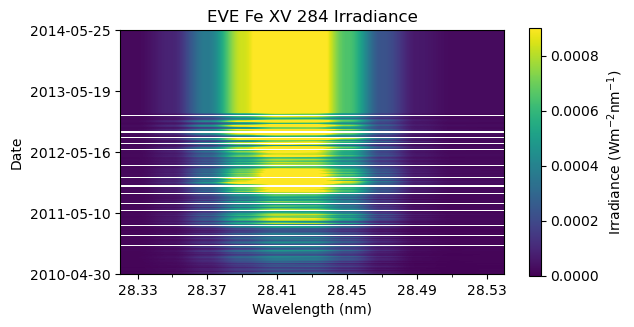

In [6]:
fig,ax=plt.subplots()
irradiance=np.stack(original_df['irradiance'].values)
sc=ax.imshow(irradiance,
             aspect=5e-8 * len(selected_band.loc[index]['Wavelength Index']),
             origin='lower',
             vmax=1.5*selected_band.loc[index]['Initial Guess'][0])

ax.set_xlabel('Wavelength (nm)')
ax.set_xticks(np.arange(len(selected_band.loc[index]['Wavelength Index'])))
ax.set_xticklabels(np.round(wavelength_full[ selected_band.loc[index]['Wavelength Index'] ],2))
# add minor and major tick of x axis
ax.xaxis.set_major_locator(plt.MultipleLocator(2))
ax.xaxis.set_minor_locator(plt.MultipleLocator(1))

ax.set_ylabel('Date')
ax.set_yticks(np.linspace(0,len(original_df),5))
ax.set_yticklabels([original_df.index[i].date() for i in np.linspace(0,len(original_df)-1,5).astype(int)])

ax.set_title('EVE '+selected_band.loc[index]['Line Name']+' Irradiance')

cbar = plt.colorbar(sc,shrink=0.55)
cbar.set_label(r'Irradiance ($\rm{W m^{-2} nm^{-1})}$')

plt.tight_layout()

# fit_10s

In [7]:
with open('./data/fit_10s/fit_10s_'+selected_band.loc[index]['Line Name']+'.pkl', 'rb') as file:
        fit_df=pickle.load(file)

In [8]:
fit_df

,time,amplitude,mean,stddev,pcov,eclipse_flag
0,2010-04-30 00:00:00,0.000288,28.419144,0.030494,"[[1.9798630189108186e-11, 1.368624028486878e-1...",0
1,2010-04-30 00:00:10,0.000293,28.418250,0.030334,"[[1.8334188418350036e-11, 1.3454459477614507e-...",0
2,2010-04-30 00:00:20,0.000294,28.419048,0.029899,"[[1.9679590302419513e-11, 9.421308591893088e-1...",0
3,2010-04-30 00:00:30,0.000286,28.418323,0.030441,"[[1.7122814505779324e-11, 1.3582391635948427e-...",0
4,2010-04-30 00:00:40,0.000293,28.418767,0.030255,"[[1.815121986757026e-11, 1.14750577234308e-13,...",0
...,...,...,...,...,...,...
12678115,2014-05-25 23:59:19,0.000742,28.418075,0.031175,"[[6.285225967096202e-11, 3.1546310044705636e-1...",0
12678116,2014-05-25 23:59:29,0.000731,28.418166,0.031438,"[[6.596228484016476e-11, 3.863280810085934e-13...",0
12678117,2014-05-25 23:59:39,0.000731,28.418032,0.030728,"[[7.217053684020475e-11, 2.8262956483681737e-1...",0
12678118,2014-05-25 23:59:49,0.000738,28.417932,0.031341,"[[6.829676823120791e-11, 3.9078738929266386e-1...",0


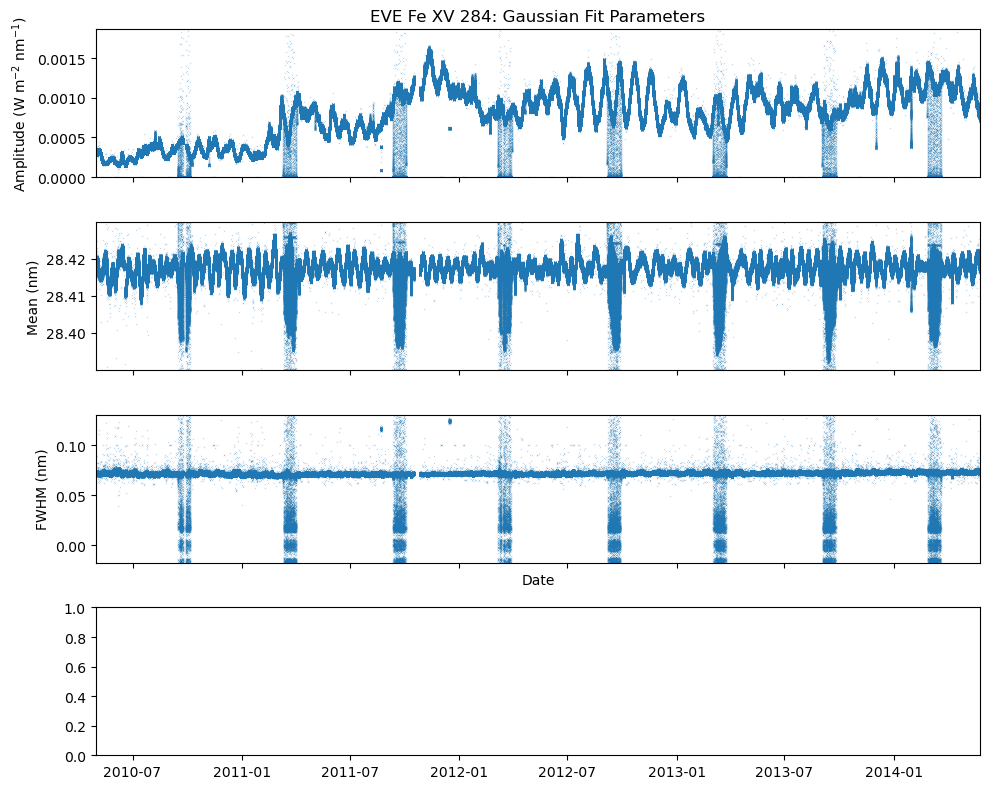

In [ ]:
# This plot takes 9 min

para_err=fit_df.apply(lambda x: np.sqrt(np.diag(x['pcov'])),axis=1)
para=fit_df[['amplitude','mean','stddev']].apply(lambda row: np.array(row), axis=1)

# create a df with para,para_err,time
para_df=pd.DataFrame({'para':para,'para_err':para_err,'time':fit_df['time']})
para_df.set_index('time',inplace=True)

fig,axs=plt.subplots(4,1,
                figsize=(10,8),
                sharex=True,)

axs[0].scatter(para_df.index,np.stack(para_df['para'].values)[:, 0],s=0.003,marker='x',label='amplitude')
# axs[0].scatter(para_df['time'],np.stack(para_df['para_err'].values)[:, 0],s=0.003,marker='x',label='amplitude_err')
axs[0].set_ylabel('Amplitude (W m$^{-2}$ nm$^{-1}$)')

upper_percentile=np.nanpercentile(np.stack(para_df['para'].values)[:, 0],99.9)
axs[0].set_ylim(0.,1.2*upper_percentile)

axs[1].scatter(para_df.index,np.stack(para_df['para'].values)[:, 1],s=0.003,marker='x',label='mean')
# axs[1].scatter(para_df['time'],np.stack(para_df['para_err'].values)[:, 1],s=0.003,marker='x',label='mean_err')
axs[1].set_ylabel('Mean (nm)')
upper_percentile=np.nanpercentile(np.stack(para_df['para'].values)[:, 1],99.8)
lower_percentile=np.nanpercentile(np.stack(para_df['para'].values)[:, 1],0.1)
axs[1].set_ylim(lower_percentile,upper_percentile+0.1*(upper_percentile-lower_percentile))

axs[2].scatter(para_df.index,gaussian_sigma_to_fwhm*np.stack(para_df['para'].values)[:, 2],s=0.003,marker='x',label='stddev')
# axs[2].scatter(para_df['time'],np.stack(para_df['para_err'].values)[:, 2],s=0.003,marker='x',label='stddev_err')
axs[2].set_ylabel('FWHM (nm)')
upper_percentile=np.nanpercentile(gaussian_sigma_to_fwhm*np.stack(para_df['para'].values)[:, 2],99.95)
lower_percentile=np.nanpercentile(gaussian_sigma_to_fwhm*np.stack(para_df['para'].values)[:, 2],0.05)
axs[2].set_ylim(lower_percentile,upper_percentile)

axs[2].set_xlabel('Date')
# axs[2].set_xlim(para_df['time'].iloc[0],para_df['time'].iloc[-1])

axs[0].set_title('EVE '+ selected_band.loc[index]['Line Name'] +': Gaussian Fit Parameters')

axs[0].set_xlim(para_df.index[0],para_df.index[-1])
    
plt.tight_layout()

# Day

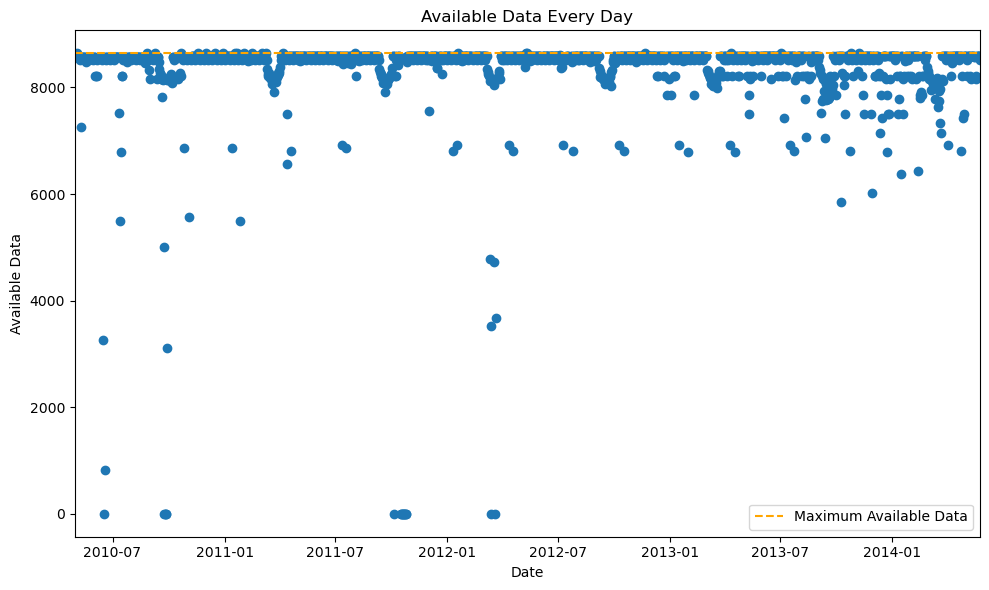

In [6]:
# for index in selected_band.index[:]:
index=22
with open('./data/daily_df/daily_df_'+selected_band.loc[index]['Line Name']+'.pkl', 'rb') as file:
    daily_df=pickle.load(file)


    fig,ax=plt.subplots(figsize=(10,6))
    ax.scatter(daily_df.index,daily_df['available_data'],)
    ax.set_xlabel('Date')
    ax.set_ylabel('Available Data')
    # add a dashed line at y=8640
    ax.axhline(y=8640, color='orange', linestyle='--',label='Maximum Available Data')
    ax.set_title('Available Data Every Day')
    ax.legend()
    ax.set_xlim(daily_df.index[0],daily_df.index[-1])
    plt.tight_layout()

In [5]:
daily_df.index

DatetimeIndex(['2010-04-30', '2010-05-01', '2010-05-02', '2010-05-03',
               '2010-05-04', '2010-05-05', '2010-05-06', '2010-05-07',
               '2010-05-08', '2010-05-09',
               ...
               '2014-05-16', '2014-05-17', '2014-05-18', '2014-05-19',
               '2014-05-20', '2014-05-21', '2014-05-22', '2014-05-23',
               '2014-05-24', '2014-05-25'],
              dtype='datetime64[ns]', name='time', length=1487, freq='D')